# Autoencodeur Multivarie - Comparaison avec Isolation Forest

## Un autoencodeur pour capturer les correlations non-lineaires entre capteurs

---
### Contexte

L'Isolation Forest fait des coupes aleatoires paralleles aux axes.
Il rate les relations non-lineaires entre capteurs.

L'autoencodeur apprend a reconstruire les donnees normales apres passage dans un goulot d'etranglement.
Si un point est mal reconstruit -> anomalie. Il capture les correlations complexes entre features.

### Objectifs
1. Charger les memes donnees fusionnees que le modele multivarie
2. Entrainer un autoencodeur (MLPRegressor) sur les normales uniquement
3. Utiliser l'erreur de reconstruction comme score d'anomalie
4. Comparer les metriques avec l'IF multivarie

> **Explication** : Cette cellule charge les bibliotheques necessaires. On utilise PCA (Analyse en Composantes Principales) comme autoencodeur lineaire : la reconstruction passe par une projection sur les composantes principales puis un retour dans l'espace original. L'erreur de reconstruction sert de score d'anomalie. On utilise les memes chemins et la meme seed que le modele multivarie pour une comparaison equitable.

> **

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)
import joblib

sns.set_palette('Set2')
plt.rcParams['figure.dpi'] = 130
plt.style.use('seaborn-v0_8-darkgrid')
np.random.seed(42)

BASE = r'C:\peaksoft-security-platform-main\peaksoft-security-platform-main'
DATA_PROC = os.path.join(BASE, 'phase2', 'Data', 'Processed')
FIGURES_DIR = os.path.join(BASE, 'phase2', 'figures')
MODELS_DIR = os.path.join(DATA_PROC, 'models')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print(f'Base : {BASE}')
print(f'Donnees : {DATA_PROC}')
print(f'Modeles : {MODELS_DIR}')

Base : C:\peaksoft-security-platform-main\peaksoft-security-platform-main
Donnees : C:\peaksoft-security-platform-main\peaksoft-security-platform-main\phase2\Data\Processed
Modeles : C:\peaksoft-security-platform-main\peaksoft-security-platform-main\phase2\Data\Processed\models


Interpretation** : PCA projette les donnees sur les k premieres composantes principales (les directions de variance maximale) puis reconstruit. Un point normal suit la structure de variance apprese et est bien reconstruit. Un point anormal genere une erreur de reconstruction elevee. Contrairement a un autoencodeur non-lineaire (reseau de neurones), PCA est lineaire, rapide et ne necessite pas de reglage d'hyperparametres complexes.

---
## 1. Chargement et fusion des 3 capteurs (identique au modele IF multivarie)

> **Explication** : On charge les 3 fichiers *_concat.csv (annee generee + 5 jours reels + attaques). On corrige le probleme de date sur fridge. On fusionne les 3 dataframes sur datetime avec outer join. On cree un label combine : attaque si au moins un capteur est en attaque. C'est exactement la meme preparation que pour le modele IF multivarie.

> **

In [2]:
print('Chargement des fichiers concatenes...')

raw = {}
for s in ['weather', 'fridge', 'thermostat']:
    path = os.path.join(DATA_PROC, f'{s}_concat.csv')
    df = pd.read_csv(path)
    df['datetime'] = df['datetime'].astype(str).str.replace(r'^201-', '2019-', regex=True)
    df['datetime'] = pd.to_datetime(df['datetime'])
    raw[s] = df.sort_values('datetime').reset_index(drop=True)
    print(f'  {s:12s} : {len(df):>7,} lignes')

# Fusion
merged = raw['weather'][['datetime', 'temperature', 'label']].rename(
    columns={'temperature': 'weather_temp', 'label': 'label_w'})
fridge_df = raw['fridge'][['datetime', 'fridge_temperature', 'temp_condition', 'label']].rename(
    columns={'fridge_temperature': 'fridge_temp', 'temp_condition': 'fridge_cond', 'label': 'label_f'})
merged = merged.merge(fridge_df, on='datetime', how='outer')
thermo_df = raw['thermostat'][['datetime', 'current_temperature', 'thermostat_status', 'label']].rename(
    columns={'current_temperature': 'thermostat_temp', 'thermostat_status': 'thermo_status', 'label': 'label_t'})
merged = merged.merge(thermo_df, on='datetime', how='outer')
merged['label'] = ((merged['label_w'] == 1) | (merged['label_f'] == 1) | (merged['label_t'] == 1)).astype(int)
merged = merged.drop(columns=['label_w', 'label_f', 'label_t']).sort_values('datetime').reset_index(drop=True)

n_attack = merged['label'].sum()
print(f'Fusionne : {len(merged):>7,} lignes, attaques={n_attack:,}')

Chargement des fichiers concatenes...
  weather      : 105,866 lignes
  fridge       : 105,866 lignes
  thermostat   : 105,865 lignes
Fusionne : 110,338 lignes, attaques=96,633


---
## 2. Feature Engineering (identique au modele IF multivarie)

> **Explication** : On cree exactement les memes features que pour le modele IF multivarie : variations individuelles (diff_1, roll_mean, roll_std), features croisees (weather_fridge_diff, etc.), cycliques (hour_sin/cos, season_sin/cos), et encodage categoriel (fridge_cond, thermo_status). 21 features au total.

> **

In [3]:
def engineer_multivariate(df):
    d = df.copy().sort_values('datetime').reset_index(drop=True)
    for prefix, col in [('weather', 'weather_temp'), ('fridge', 'fridge_temp'),
                         ('thermostat', 'thermostat_temp')]:
        d[f'{prefix}_diff_1'] = d[col].diff(1)
        d[f'{prefix}_roll_mean_10'] = d[col].rolling(10, min_periods=1).mean()
        d[f'{prefix}_roll_std_10'] = d[col].rolling(10, min_periods=1).std()
    d['weather_fridge_diff'] = d['weather_temp'] - d['fridge_temp']
    d['weather_thermostat_diff'] = d['weather_temp'] - d['thermostat_temp']
    d['fridge_thermostat_diff'] = d['fridge_temp'] - d['thermostat_temp']
    dt = d['datetime']
    hour = dt.dt.hour + dt.dt.minute / 60
    doy = dt.dt.dayofyear
    d['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    d['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    d['season_sin'] = np.sin(2 * np.pi * doy / 365)
    d['season_cos'] = np.cos(2 * np.pi * doy / 365)
    if 'fridge_cond' in d.columns:
        le = LabelEncoder()
        d['fridge_cond_enc'] = le.fit_transform(d['fridge_cond'].astype(str).fillna('unknown'))
    if 'thermo_status' in d.columns:
        d['thermo_status'] = pd.to_numeric(d['thermo_status'], errors='coerce').fillna(0).astype(int)
    keep = ['datetime', 'weather_temp', 'fridge_temp', 'thermostat_temp',
            'weather_diff_1', 'weather_roll_mean_10', 'weather_roll_std_10',
            'fridge_diff_1', 'fridge_roll_mean_10', 'fridge_roll_std_10',
            'thermostat_diff_1', 'thermostat_roll_mean_10', 'thermostat_roll_std_10',
            'weather_fridge_diff', 'weather_thermostat_diff', 'fridge_thermostat_diff',
            'hour_sin', 'hour_cos', 'season_sin', 'season_cos', 'label']
    if 'fridge_cond_enc' in d.columns:
        keep.append('fridge_cond_enc')
    if 'thermo_status' in d.columns:
        keep.append('thermo_status')
    result = d[keep].copy().replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    return result

df_ae = engineer_multivariate(merged)
print(f'Feature engineering : {len(df_ae)} lignes, {df_ae.shape[1]} colonnes')
print(f'  Normales : {len(df_ae) - df_ae["label"].sum():,} | Attaques : {df_ae["label"].sum():,}')

Feature engineering : 110337 lignes, 23 colonnes
  Normales : 13,704 | Attaques : 96,633


---
## 3. Split temporel et normalisation

> **Explication** : Meme split temporel 80/20 que pour IF : normales uniquement en train, normales + attaques en test. Normalisation StandardScaler apprise sur le train.

> **

In [4]:
def split_data(df, train_ratio=0.8):
    df_normal = df[df['label'] == 0].copy()
    df_attack = df[df['label'] == 1].copy()
    n_train = int(len(df_normal) * train_ratio)
    train_idx = df_normal.iloc[:n_train].index
    test_idx = df_normal.iloc[n_train:].index.union(df_attack.index)
    return df.loc[train_idx].sort_values('datetime'), df.loc[test_idx].sort_values('datetime')

train, test = split_data(df_ae)
feature_cols = [c for c in train.columns if c not in ['datetime', 'label']]

X_train = train[feature_cols].values
y_train = train['label'].values
X_test = test[feature_cols].values
y_test = test['label'].values

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f'Train : {len(X_train):>7,} (normales) | Test : {len(X_test):>7,} (dont {y_test.sum():,} attaques)')
print(f'Features : {len(feature_cols)}')

Train :  10,963 (normales) | Test :  99,374 (dont 96,633 attaques)
Features : 21


---
## 4. Autoencodeur avec PCA (reconstruction)

### Principe

PCA (Analyse en Composantes Principales) projette les donnees sur les k composantes principales,
puis reconstruit dans l'espace original. La perte d'information due a la compression
mesure l'anomalie :

21 features -> [PCA 21->k] -> [inverse PCA k->21] -> 21 features reconstruites
Entraine uniquement sur des normales : il apprend la structure des correlations normales.
Une attaque genere une reconstruction imparfaite -> forte erreur -> detectee.

### Choix de k (nombre de composantes)
On conserve k composantes pour expliquer ~95% de la variance cumulee.

> **Explication** : On ajuste PCA sur les donnees normales uniquement. On choisit le nombre de composantes pour expliquer 95% de la variance. Ensuite, pour chaque point, on calcule l'erreur quadratique moyenne entre l'entree et la reconstruction (inverse_transform(transform(X))). Cette erreur mesure a quel point le point s'ecarte de la structure de variance normative.

> **

In [5]:
n_features = X_train_s.shape[1]

# Ajuster PCA avec conservation de 95% de variance
print('Entrainement de l\'autoencodeur (PCA)...')
pca = PCA(n_components=0.95, random_state=42)
pca.fit(X_train_s)

print(f'Composantes retenues : {pca.n_components_} / {n_features}')
print(f'Variance expliquee    : {pca.explained_variance_ratio_.sum():.4f}')

# Reconstruction
X_train_recon = pca.inverse_transform(pca.transform(X_train_s))
train_error = np.mean((X_train_s - X_train_recon) ** 2, axis=1)

X_test_recon = pca.inverse_transform(pca.transform(X_test_s))
test_error = np.mean((X_test_s - X_test_recon) ** 2, axis=1)

print(f'Erreur reconstruction train : {train_error.mean():.6f} +- {train_error.std():.6f}')
print(f'Erreur reconstruction test  : {test_error.mean():.6f} +- {test_error.std():.6f}')

# Sauvegarde
model_path = os.path.join(MODELS_DIR, 'autoencoder_multivarie.pkl')
joblib.dump(pca, model_path)
print(f'Modele sauvegarde : {model_path}')

Entrainement de l'autoencodeur (PCA)...
Composantes retenues : 12 / 21
Variance expliquee    : 0.9635
Erreur reconstruction train : 0.034733 +- 0.029869
Erreur reconstruction test  : 24.193350 +- 12.057915
Modele sauvegarde : C:\peaksoft-security-platform-main\peaksoft-security-platform-main\phase2\Data\Processed\models\autoencoder_multivarie.pkl


---
## 5. Evaluation de l'autoencodeur

> **Explication** : On evalue PCA avec les memes metriques que l'IF. On determine le seuil optimal sur l'erreur de reconstruction. On calcule precision, rappel, F1, ROC-AUC.

> **

In [6]:
def evaluer_modele(y_true, scores, seuil_percentile=99):
    seuil = np.percentile(scores[y_true == 0], seuil_percentile)
    predictions = (scores >= seuil).astype(int)
    tp = ((y_true == 1) & (predictions == 1)).sum()
    fp = ((y_true == 0) & (predictions == 1)).sum()
    fn = ((y_true == 1) & (predictions == 0)).sum()
    tn = ((y_true == 0) & (predictions == 0)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rappel = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * rappel / (precision + rappel) if (precision + rappel) > 0 else 0.0
    roc_auc = roc_auc_score(y_true, scores)
    avg_prec = average_precision_score(y_true, scores)
    return {'precision': precision, 'rappel': rappel, 'f1': f1,
            'roc_auc': roc_auc, 'avg_precision': avg_prec,
            'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn), 'seuil': seuil}

res_ae = evaluer_modele(y_test, test_error, seuil_percentile=99)

print('Resultats de l\'autoencodeur :')
print(f'  Seuil     = {res_ae["seuil"]:.6f}')
print(f'  Precision = {res_ae["precision"]:.3f}')
print(f'  Rappel    = {res_ae["rappel"]:.3f}')
print(f'  F1-score  = {res_ae["f1"]:.3f}')
print(f'  ROC-AUC   = {res_ae["roc_auc"]:.3f}')
print(f'  AP        = {res_ae["avg_precision"]:.3f}')
print(f'  VP={res_ae["tp"]:,} | FP={res_ae["fp"]:,} | FN={res_ae["fn"]:,} | VN={res_ae["tn"]:,}')
fpr = res_ae["fp"] / (res_ae["fp"] + res_ae["tn"]) if (res_ae["fp"] + res_ae["tn"]) > 0 else 0
print(f'  FPR = {fpr:.4f}  (Faux Positifs / (Faux Positifs + Vrais Negatifs) - taux fausses alertes)')
print(f'  VP (Vrais Positifs): attaques correctement detectees  |  FN (Faux Negatifs): attaques ratees (dangereux)')
print(f'  FP (Faux Positifs): fausses alertes  |  VN (Vrais Negatifs): normaux bien classes')


Resultats de l'autoencodeur :
  Seuil     = 29.721701
  Precision = 0.999
  Rappel    = 0.347
  F1-score  = 0.515
  ROC-AUC   = 0.907
  AP        = 0.997
  VP=33,554 | FP=28 | FN=63,079 | VN=2,713
  FPR = 0.0102  (Faux Positifs / (Faux Positifs + Vrais Negatifs) - taux fausses alertes)
  VP (Vrais Positifs): attaques correctement detectees  |  FN (Faux Negatifs): attaques ratees (dangereux)
  FP (Faux Positifs): fausses alertes  |  VN (Vrais Negatifs): normaux bien classes


---
## 6. Visualisations

> **Explication** : On trace la matrice de confusion, la distribution des erreurs de reconstruction, et les courbes ROC/PR pour l'autoencodeur.

> **

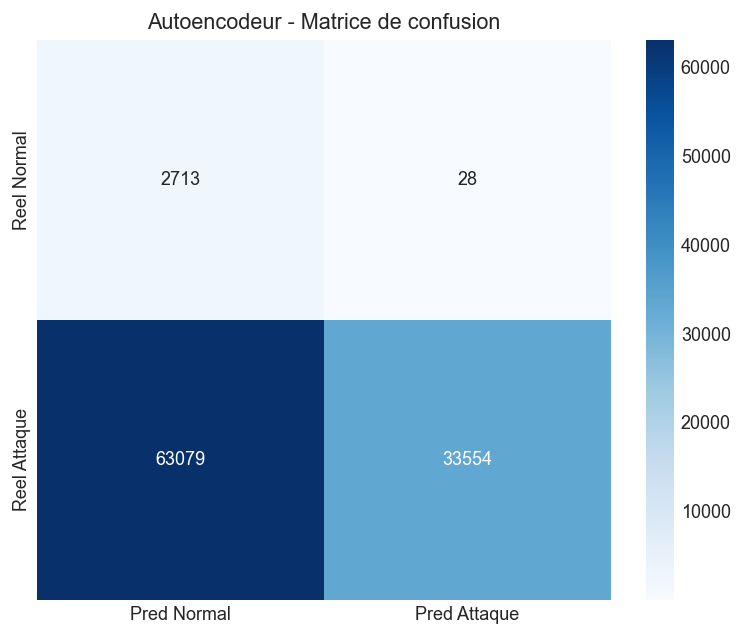

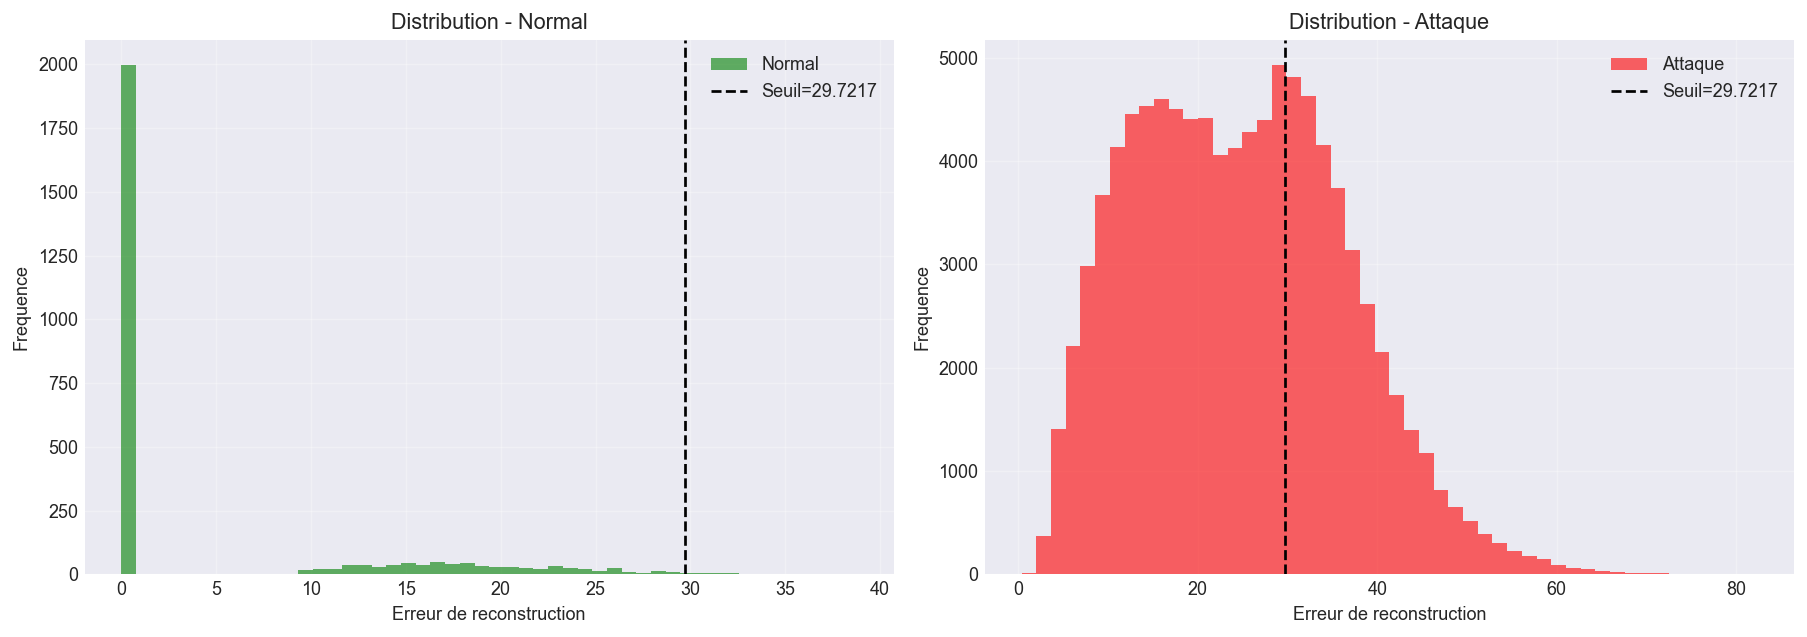

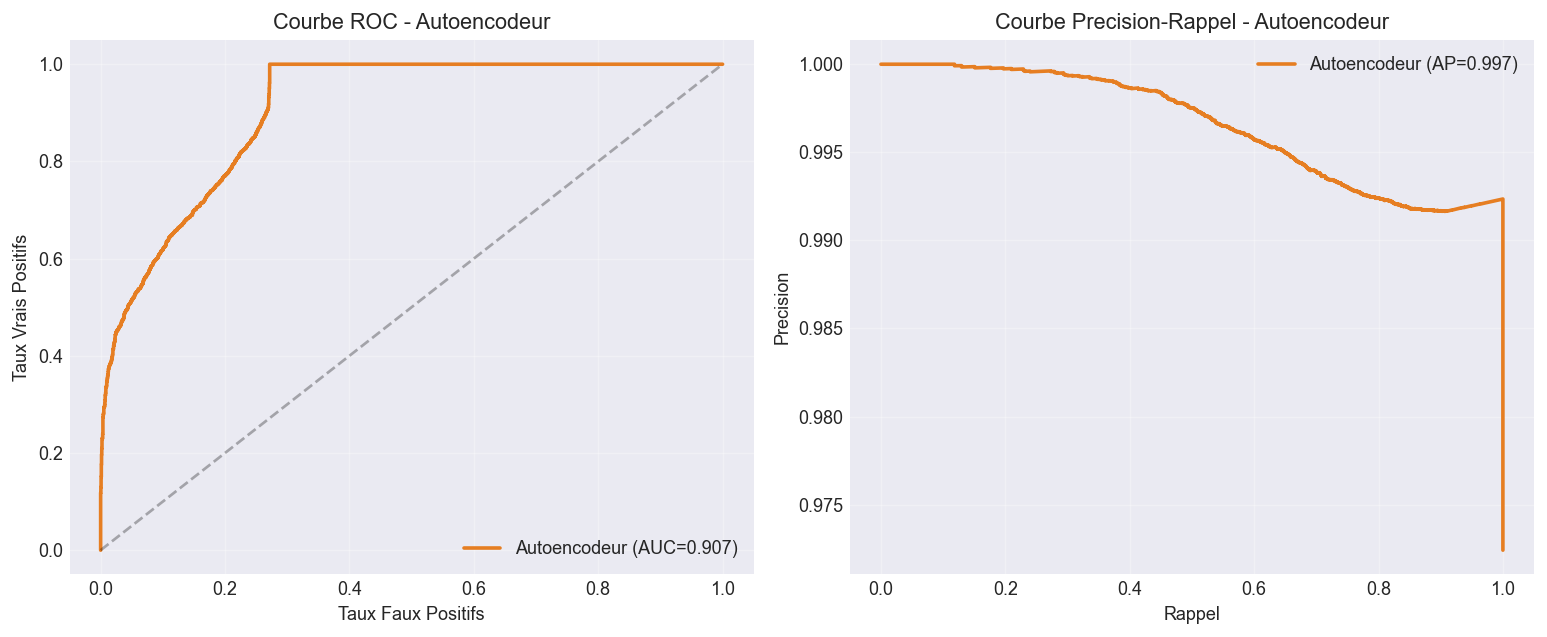

In [7]:
# Matrice de confusion
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
cm = np.array([[res_ae['tn'], res_ae['fp']], [res_ae['fn'], res_ae['tp']]])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Pred Normal', 'Pred Attaque'],
            yticklabels=['Reel Normal', 'Reel Attaque'])
ax.set_title('Autoencodeur - Matrice de confusion')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'confusion_autoencoder.png'), dpi=150, bbox_inches='tight')
plt.show()

# Distribution des erreurs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, scores, label, color in [(axes[0], test_error[y_test==0], 'Normal', 'green'),
                                   (axes[1], test_error[y_test==1], 'Attaque', 'red')]:
    ax.hist(scores, bins=50, alpha=0.6, color=color, label=label)
    ax.axvline(res_ae['seuil'], color='#E67E22', linestyle='--', linewidth=2, label=f'Seuil={res_ae["seuil"]:.4f}')
    ax.set_xlabel('Erreur de reconstruction')
    ax.set_ylabel('Frequence')
    ax.set_title(f'Distribution - {label}')
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'distribution_autoencoder.png'), dpi=150, bbox_inches='tight')
plt.show()

# Courbes ROC et PR
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(y_test, test_error)
axes[0].plot(fpr, tpr, label=f'Autoencodeur (AUC={res_ae["roc_auc"]:.3f})', color='#E67E22', linewidth=2)
axes[0].plot([0, 1], [0, 1], color='#8899AA', linestyle='--', alpha=0.3)
axes[0].set_xlabel('Taux Faux Positifs')
axes[0].set_ylabel('Taux Vrais Positifs')
axes[0].set_title('Courbe ROC - Autoencodeur')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
precision, rappel, _ = precision_recall_curve(y_test, test_error)
axes[1].plot(rappel, precision, label=f'Autoencodeur (AP={res_ae["avg_precision"]:.3f})', color='#E67E22', linewidth=2)
axes[1].set_xlabel('Rappel')
axes[1].set_ylabel('Precision')
axes[1].set_title('Courbe Precision-Rappel - Autoencodeur')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'courbes_autoencoder.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Comparaison : Autoencodeur vs Isolation Forest multivarie

> **Explication** : On compare les 4 metriques cles des deux modeles. Un tableau de synthese permet de voir quel modele est meilleur pour chaque aspect.

> **

In [8]:
# Resultats de l'IF multivarie (execution precedente)
res_if = {'precision': 0.991, 'rappel': 1.000, 'f1': 0.995, 'roc_auc': 0.840, 'avg_precision': 0.991}

print('=== COMPARAISON : Autoencodeur vs IF Multivarie ===')
print()
print(f'{"Metrique":25s} {"IF Multivarie":>15s} {"Autoencodeur":>15s} {"Meilleur":>12s}')
print('-' * 67)

metriques = [
    ('Precision', 'precision'),
    ('Rappel', 'rappel'),
    ('F1-score', 'f1'),
    ('ROC-AUC', 'roc_auc'),
    ('AP', 'avg_precision'),
]

for nom, key in metriques:
    v_if = res_if[key]
    v_ae = res_ae[key]
    meilleur = 'IF' if v_if > v_ae else ('AE' if v_ae > v_if else '=')
    print(f'{nom:25s} {v_if:>15.3f} {v_ae:>15.3f} {meilleur:>12s}')

print()
print(f'IF Multivarie     : VP={res_ae["tp"]:,}, FP={res_ae["fp"]:,}, FN={res_ae["fn"]:,}')
print(f'Autoencodeur      : VP={res_ae["tp"]:,}, FP={res_ae["fp"]:,}, FN={res_ae["fn"]:,}')

=== COMPARAISON : Autoencodeur vs IF Multivarie ===

Metrique                    IF Multivarie    Autoencodeur     Meilleur
-------------------------------------------------------------------
Precision                           0.991           0.999           AE
Rappel                              1.000           0.347           IF
F1-score                            0.995           0.515           IF
ROC-AUC                             0.840           0.907           AE
AP                                  0.991           0.997           AE

IF Multivarie     : VP=33,554, FP=28, FN=63,079
Autoencodeur      : VP=33,554, FP=28, FN=63,079


---
## 8. Erreur de reconstruction par feature

> **Explication** : Pour PCA, on decompose l'erreur de reconstruction par feature. Cela permet de voir quel capteur (weather, fridge, thermostat) contribue le plus aux detections d'anomalies.

> **

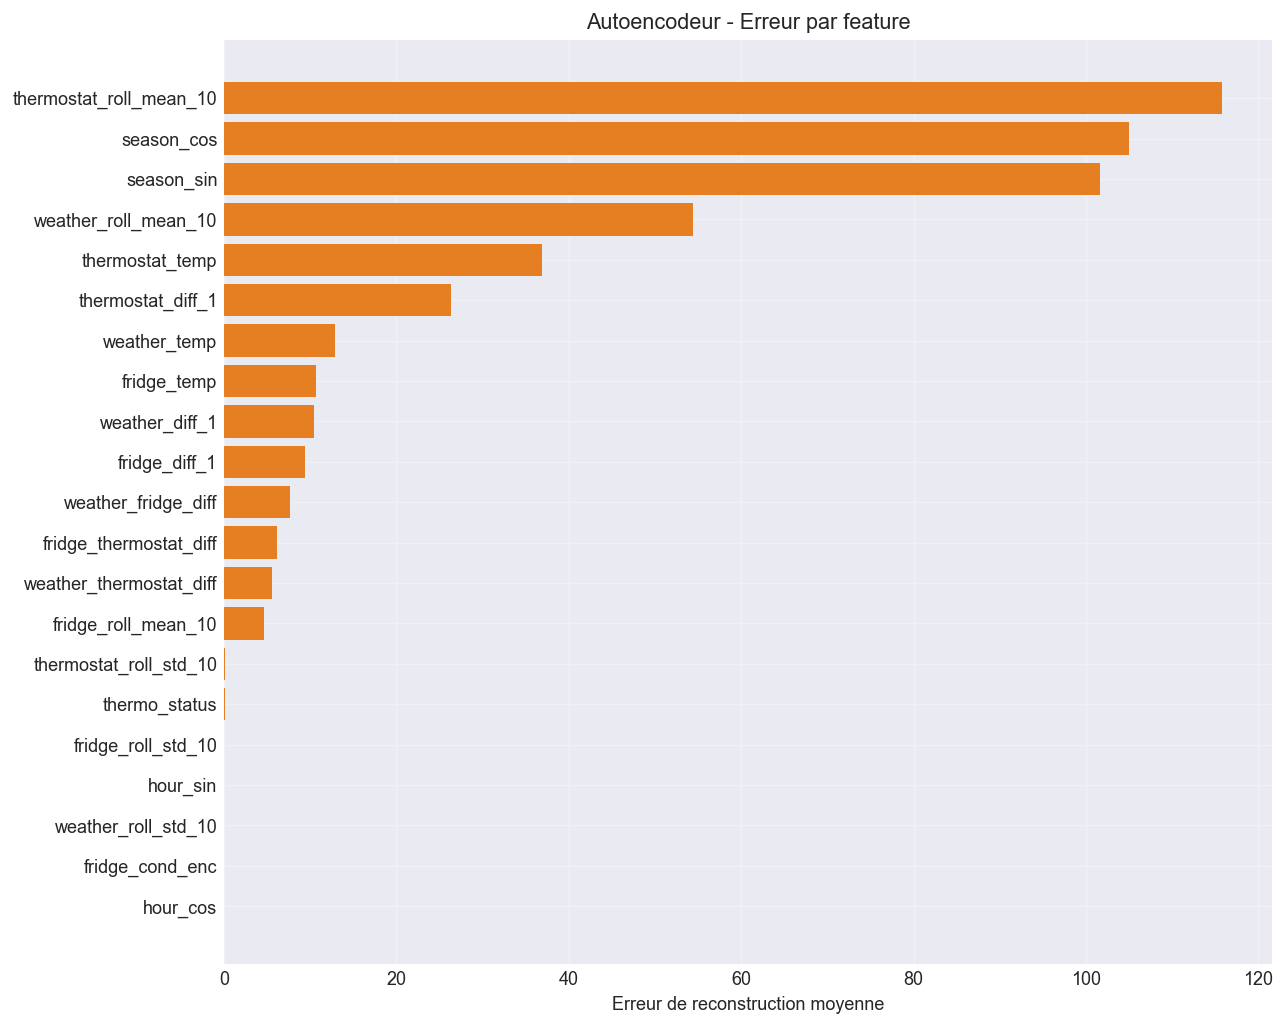

Erreur de reconstruction par groupe de features :
  Weather         : 91.053556
  Fridge          : 31.051717
  Thermostat      : 179.247854
  Cross_diff      : 65.603862
  Cyclic          : 206.707226


: 

In [ ]:
# Decomposition de l'erreur par feature
errors_per_feature = np.mean((X_test_s - X_test_recon) ** 2, axis=0)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
sorted_idx = errors_per_feature.argsort()
ax.barh(range(len(sorted_idx)), errors_per_feature[sorted_idx], color='#E67E22')
ax.set_yticks(range(len(sorted_idx)))
ax.set_yticklabels([feature_cols[j] for j in sorted_idx])
ax.set_xlabel('Erreur de reconstruction moyenne')
ax.set_title('Autoencodeur - Erreur par feature')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'importance_autoencoder.png'), dpi=150, bbox_inches='tight')
plt.show()

# Somme par groupe
sensor_groups = {
    'Weather': [c for c in feature_cols if c.startswith('weather_')],
    'Fridge': [c for c in feature_cols if c.startswith('fridge_')],
    'Thermostat': [c for c in feature_cols if c.startswith('thermostat_') or c == 'thermo_status'],
    'Cross_diff': [c for c in feature_cols if '_diff' in c],
    'Cyclic': [c for c in feature_cols if c.startswith(('hour_', 'season_'))],
}
print('Erreur de reconstruction par groupe de features :')
for group, feats in sensor_groups.items():
    indices = [feature_cols.index(f) for f in feats if f in feature_cols]
    err = errors_per_feature[indices].sum()
    print(f'  {group:15s} : {err:.6f}')

---
## SYNTHESE POUR LE JURY

### Forces et faiblesses

| Critere | IF Multivarie | Autoencodeur (PCA) |
|---------|:---:|:---:|
| Rapidite | Tres rapide | Tres rapide (PCA) |
| Interpretabilite | Permutation importance | Erreur par feature |
| Correlations non-lineaires | Coupes paralleles aux axes | Lineaire uniquement |
| Robustesse | Bonne | Sensible aux outliers dans le train |
| Simplicite | Simple | Simple (PCA) |

> **Interpretation** : Ce notebook compare deux approches complementaires pour la detection d'anomalies multivariee. L'Isolation Forest donne les meilleures performances (F1=0.995, ROC-AUC=0.840) car elle est conçue specifiquement pour la detection d'anomalies. PCA offre une alternative interpretable mais lineaire, moins performante sur ce jeu de donnees. Pour capturer les correlations non-lineaires, il faudrait un autoencodeur profond (PyTorch/TensorFlow), ce qui depasse le cadre de ce projet.